## Code for splitting the parcels simulation output into individual locations

## Be sure to check labels of plots, depending on either limited max depth or absolute max depth releases

In [1]:
import json

import numpy as np
import xarray as xr
import netCDF4 as nc
import pandas as pd
# import parcels
# import matplotlib.pyplot as plt
# import matplotlib.gridspec as gridspec

# import cmocean

# from glob import glob
# from copy import copy
# from scipy import interpolate
# from datetime import timedelta
# from matplotlib.lines import Line2D


# from parcels import (
#     AdvectionRK4_3D,
#     Field,
#     FieldSet,
#     Geographic,
#     GeographicPolar,
#     JITParticle,
#     ParticleSet,
#     ScipyParticle,
#     Variable,
# )

import plotly
import plotly.graph_objects as go
from glob import glob

In [2]:
#### PLOTTING VENT ####
location = 8 # select integer of vent to plot

In [12]:
# ===============================================================================
# Set up model runs:

# model dimensions: 2D vs 3D
ndim = 3     # 2 for 2D simulations; 3 for 3D simulations

# time
year_start = 2022
year_end = 2023
run_period = 60  # days; Total runtime of simulation
time_step = 2   # hours; Time increment of particle tracking
release_period = 30 # days; consecutive days of release

# particle release
release_depth = 'max_depth'  # Release depth; for 2D: 100-800m (100m-increments); for 3D: max_depth
bouncing = True  # Use displacement functions to prevent particles getting stuck
multi_particles = True # If 'True' uniform release of 'num_pts' particles within 1km radius of HTV coordinates
num_pts = 10
continuous_release = True # If 'True' release particles continuously, else release particles all at once
particle = 'passive'  # if 'passive': no vertical migration; if 'active': vertical migration

incremental_depth_release = True # If 'True' release particles at multiple depths over set increments
depth_interval = 100 #meters

# # output
# #output_name = 'reordered_num_depth_3d_multipl2_multidepth_maxdepth_100minterval_10d_5r'
# output_name = (f"reordered_num_depth_{ndim}d_multipl{num_pts}_multidepth_maxdepth_{depth_interval}minterval_{run_period}d_{release_period}r")

#output_name = 'reordered_num_depth_3d_multipl2_multidepth_maxdepth_100minterval_10d_5r'

if incremental_depth_release==True:
    output_name =(f"reordered_num_depth_{ndim}d_multipl{num_pts}_multidepth_maxdepth_{depth_interval}minterval_{run_period}d_{release_period}r")#_accuratedepths_repeat")
else:
    output_name =(f"reordered_num_depth_{ndim}d_multipl{num_pts}_singledepth_maxdepth_{run_period}d_{release_period}r")
#output_name = 'soph_TEST_14d_dt2h_cont_release_4d_100part_Sep2022'
# =========================================================================


In [13]:
output_name

'reordered_num_depth_3d_multipl10_multidepth_maxdepth_100minterval_60d_30r'

In [15]:
#if in current folder just leave blank ''
file_location = '../../simulations/output/time_part_num_testing/'

n_locations = 13 # number of release locations

# Open simulation dataset

ds = xr.open_zarr(file_location + output_name + '.zarr')

#extract vent data from .json
with open(file_location + "sim_metadata_tmp" + output_name + ".json", "r") as f:
    metadata = json.load(f)

n_depths_per_location = metadata["n_depths_per_site"]
n_depths_per_location = np.array(n_depths_per_location) #convert to np.array
vent_lon = metadata["vent_lon"]
vent_lat = metadata["vent_lat"]

In [16]:
ds

<xarray.Dataset> Size: 4GB
Dimensions:     (trajectory: 121179, obs: 720)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 713 714 715 716 717 718 719
  * trajectory  (trajectory) int64 969kB 0 1 2 3 ... 121175 121176 121177 121178
Data variables:
    d2s         (trajectory, obs) float32 349MB dask.array<chunksize=(3909, 1), meta=np.ndarray>
    d2seabed    (trajectory, obs) float32 349MB dask.array<chunksize=(3909, 1), meta=np.ndarray>
    dU          (trajectory, obs) float32 349MB dask.array<chunksize=(3909, 1), meta=np.ndarray>
    dV          (trajectory, obs) float32 349MB dask.array<chunksize=(3909, 1), meta=np.ndarray>
    dZ          (trajectory, obs) float32 349MB dask.array<chunksize=(3909, 1), meta=np.ndarray>
    lat         (trajectory, obs) float32 349MB dask.array<chunksize=(3909, 1), meta=np.ndarray>
    lon         (trajectory, obs) float32 349MB dask.array<chunksize=(3909, 1), meta=np.ndarray>
    temp        (trajectory, obs) float32 349MB dask.array<chunksize=(3909, 1), meta=np.ndarray>
    time        (trajectory, obs) datetime64[ns] 698MB dask.array<chunksize=(3909, 1), meta=np.ndarray>
    z           (trajectory, obs) float32 349MB dask.array<chunksize=(3909, 1), meta=np.ndarray>
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        DisplacementParticledisplacedisplace_zAdvectionRK...
    parcels_mesh:           spherical
    parcels_version:        3.0.4

In [6]:
vals = ds["lat"].isel(obs=0).values[300:300+360]
vals

array([6.8035245, 6.8035245, 6.8035245, 6.8035245, 6.8035245, 6.8035245,
       6.8035245, 6.8035245, 6.8035245, 6.8035245, 6.8035245, 6.8035245,
       6.8035245, 6.8035245, 6.8035245, 6.8035245, 6.8035245, 6.8035245,
       6.8035245, 6.8035245, 6.8035245, 6.8035245, 6.8035245, 6.8035245,
       6.8035245, 6.8035245, 6.8035245, 6.8035245, 6.8035245, 6.8035245,
       6.361958 , 6.361958 , 6.361958 , 6.361958 , 6.361958 , 6.361958 ,
       6.361958 , 6.361958 , 6.361958 , 6.361958 , 6.361958 , 6.361958 ,
       6.361958 , 6.361958 , 6.361958 , 6.361958 , 6.361958 , 6.361958 ,
       6.361958 , 6.361958 , 6.361958 , 6.361958 , 6.361958 , 6.361958 ,
       6.361958 , 6.361958 , 6.361958 , 6.361958 , 6.361958 , 6.361958 ,
       6.363857 , 6.363857 , 6.363857 , 6.363857 , 6.363857 , 6.363857 ,
       6.363857 , 6.363857 , 6.363857 , 6.363857 , 6.363857 , 6.363857 ,
       6.363857 , 6.363857 , 6.363857 , 6.363857 , 6.363857 , 6.363857 ,
       6.363857 , 6.363857 , 6.363857 , 6.363857 , 

In [7]:
count = np.sum(vals == 3.7489579)
print(count)

30


In [17]:
# Print the number of releases at each site as an array, according to the .json metadata
releases_per_site = [value*num_pts for value in metadata['n_depths_per_site']]
releases_per_site

[330, 330, 360, 330, 290, 290, 260, 360, 360, 330, 290, 200, 200]

In [18]:
# Print the number of 
# Loop to see if the final values for each release match the number they should (n_depths_per_site in metadata)
lat = ds["lat"].isel(obs=0).values # from simulation .zarr file

start = 0

for section_length in releases_per_site: #from metadata .json
    end = start + section_length # end = 0 + 330
    vals = lat[start:end] #vals = lat[0:330]
    count = np.sum(np.isclose(vals, vals[0], atol=0.1))
    #count = np.sum(vals == vals[-1]) 
    print(count)

    start = end

330
330
360
330
290
290
260
360
339
309
269
200
179


In [9]:
lat[0:300]

array([6.798958 , 6.798958 , 6.798958 , 6.798958 , 6.798958 , 6.798958 ,
       6.798958 , 6.798958 , 6.798958 , 6.798958 , 6.798958 , 6.798958 ,
       6.798958 , 6.798958 , 6.798958 , 6.798958 , 6.798958 , 6.798958 ,
       6.798958 , 6.798958 , 6.798958 , 6.798958 , 6.798958 , 6.798958 ,
       6.798958 , 6.798958 , 6.798958 , 6.798958 , 6.798958 , 6.798958 ,
       6.798958 , 6.798958 , 6.798958 , 6.800857 , 6.800857 , 6.800857 ,
       6.800857 , 6.800857 , 6.800857 , 6.800857 , 6.800857 , 6.800857 ,
       6.800857 , 6.800857 , 6.800857 , 6.800857 , 6.800857 , 6.800857 ,
       6.800857 , 6.800857 , 6.800857 , 6.800857 , 6.800857 , 6.800857 ,
       6.800857 , 6.800857 , 6.800857 , 6.800857 , 6.800857 , 6.800857 ,
       6.800857 , 6.800857 , 6.800857 , 6.800857 , 6.800857 , 6.800857 ,
       6.8006988, 6.8006988, 6.8006988, 6.8006988, 6.8006988, 6.8006988,
       6.8006988, 6.8006988, 6.8006988, 6.8006988, 6.8006988, 6.8006988,
       6.8006988, 6.8006988, 6.8006988, 6.8006988, 

In [13]:
np.set_printoptions(threshold=np.inf)
lat

array([  6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,
         6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,
         6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,
         6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,
         6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,
         6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,   6.798958 ,
         6.798958 ,   6.798958 ,   6.798958 ,   6.800857 ,   6.800857 ,
         6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,
         6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,
         6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,
         6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,
         6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,
         6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,   6.800857 ,
         6.800857 ,   6.8006988,   6.8006988,   6.8006988,   6.8

### Bathymetry data

In [9]:
# load bathymetry data etc

data_path_MERC = '/bucket/MitaraiU/Users/heng/GLORYS12/'


# In[4]:


def load_mercator_fields(year_start, months_start, year_end):
    # declare variables
    uv_temp = []
    w_temp = []
    t_temp = []
    uv_files_start = []
    w_files_start = []
    t_files_start = []
    # set data paths
    data_path_start = '/bucket/MitaraiU/Users/heng/GLORYS12/' + str(year_start) + '/'
    data_path_end = '/bucket/MitaraiU/Users/heng/GLORYS12/' + str(year_end) + '/'
    # load velocity dataset names
    for month in range(len(months_start)):
        uv_temp = sorted(glob(data_path_start + 'glo12_rg_1d-m_' + str(year_start) + str(months_start[month]) +'*_3D-uovo_hcst*.nc'))
        w_temp = sorted(glob(data_path_start + 'glo12_rg_1d-m_' + str(year_start) + str(months_start[month]) +'*_3D-wo_hcst*.nc'))
        t_temp = sorted(glob(data_path_start + 'glo12_rg_1d-m_' + str(year_start) + str(months_start[month]) +'*_3D-thetao_hcst*.nc'))
        uv_files_start = uv_files_start + uv_temp
        w_files_start = w_files_start + w_temp
        t_files_start = t_files_start + t_temp
    uv_files_end = sorted(glob(data_path_end + 'glo12_rg_1d-m_*_3D-uovo_hcst*.nc'))
    w_files_end = sorted(glob(data_path_end + 'glo12_rg_1d-m_*_3D-wo_hcst*.nc'))
    t_files_end = sorted(glob(data_path_end + 'glo12_rg_1d-m_*_3D-thetao_hcst*.nc'))
    uv_files_comb = uv_files_start + uv_files_end
    w_files_comb = w_files_start + w_files_end
    t_files_comb = t_files_start + t_files_end
    return uv_files_comb, w_files_comb, t_files_comb


# In[5]:


months_start = ["09", 10, 11, 12] # 09 not accepted as integer, so string
uv_files, w_files, t_files =load_mercator_fields(year_start, months_start, year_end)


# In[6]:


len(uv_files), len(w_files), len(t_files) # should equal to 487 


# In[7]:


import dask
with dask.config.set(**{'array.slicing.split_large_chunks': False}): # this line needed
    t=xr.open_mfdataset(t_files,combine='nested', concat_dim = 'time')


# In[8]:


# Load landmask and bathymetry
mask_bathy_path = data_path_MERC + 'GLO-MFC_001_024_mask_bathy.nc' 
mask_bathy      = nc.Dataset(mask_bathy_path)

landmask = mask_bathy['mask']  # dim=(depth=50, lat=2041, lon=4320); Land: 0, Ocean: 1

# Make negative of land mask (i.e. Land: 1, Ocean: 0)
landmask_negative = 1 - landmask[:]


# In[9]:


landmask_negative.shape


# In[10]:


# Load coordinates file
mesh_mask_path = data_path_MERC + 'GLO-MFC_001_024_coordinates.nc' 
mesh_mask      = nc.Dataset(mesh_mask_path)


# In[11]:


# Specify filenames, variables, and dimensions
filenames = {
    'U': {'lon': mesh_mask_path, 'lat': mesh_mask_path, 'depth': mesh_mask_path, 'data': uv_files},
    'V': {'lon': mesh_mask_path, 'lat': mesh_mask_path, 'depth': mesh_mask_path, 'data': uv_files},
    'W': {'lon': mesh_mask_path, 'lat': mesh_mask_path, 'depth': mesh_mask_path, 'data': w_files},
    'T': {'lon': mesh_mask_path, 'lat': mesh_mask_path, 'depth': mesh_mask_path, 'data': t_files}
}
variables = {
    'U': 'uo',
    'V': 'vo',
    'W': 'wo',
    'T': 'thetao'
}
dimensions = {
    'U': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'V': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'W': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'T': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'}
}

# ===============================================================================
# Indian HTV (HTV) release locations:
excel_file_path = '/flash/MitaraiU/oceanparcels/htv/lily/indianocean_accurate_perez2021_fields.xlsx' #indianocean_perez2021_fields.xlsx' 
htv_data = pd.read_excel(excel_file_path)

htv_lon = htv_data['Longitude']
htv_lat = htv_data['Latitude']
#htv_dep = htv_data['WaterDepth_m']


# In[13]:


# Run uniform point release and coordinate cleaning function
depth_data = xr.open_mfdataset(mask_bathy_path)


#=================================================================================

In [15]:
htv_data

,Vent Name,Latitude,Longitude,Depth (m),Ridge
0,Daxi,6.8000,60.1800,3450,CR
1,Wocan,6.3630,60.3030,2989,CR
2,Tianxiu,3.7500,63.7500,3450,CR
3,Tiancheng,-27.8508,63.9227,2705,SWIR
4,Onnuri,-11.4147,66.4230,2022,CIR
5,Dodo,-18.3365,65.2990,2745,CIR
6,Solitaire,-19.5569,65.8478,2606,CIR
7,Edmond,-23.9183,69.9387,3290–3320,CIR
8,Kairei,-25.3195,70.0405,2422-2450,CIR
9,Pelagia,-26.1567,71.4404,3680–3690,SEIR


In [10]:
# ==============================================================================
# Interpolate bathymetric depth at each coordinate
def int_depth_model(dataset, lon, lat):
    depths = []
    for i in range(len(lon)):
        depth = dataset['deptho'].interp(
            longitude=lon[i],
            latitude=lat[i],
            method='nearest'
        )
        depths.append(depth.values)
    return np.array(depths)

# FIND RELEASE DEPTHS PER SITE#
# ==============================================================================

In [11]:
# ==============================================================================
# BLOCK 1: Set up coordinates and compute max release depths (filtered first)

# Save original coordinates before any processing, may differ slightly after release pattern decided
original_vent_lon = htv_lon.copy()
original_vent_lat = htv_lat.copy()


######## From block 1 (which was moved below block 2)
# Interpolate seafloor depth and compute max release depth (minus 10m safety buffer)
seafloor = xr.open_mfdataset(mask_bathy_path)
max_release_depths = int_depth_model(seafloor, htv_lon, htv_lat) - 10

# Fallback for flat depth if not using incremental
if release_depth == 'max_depth':
    new_release_depth = max_release_depths
else:
    new_release_depth = [release_depth] * len(max_release_depths)

print(f"original_vent_lon: {len(original_vent_lon)}")
print(f"htv_lon after processing: {len(htv_lon)}")
print(f"max_release_depths: {len(max_release_depths)}")
# ==============================================================================

original_vent_lon: 13
htv_lon after processing: 13
max_release_depths: 13


In [12]:
seafloor = xr.open_mfdataset(mask_bathy_path)

In [16]:
max_release_depths = int_depth_model(seafloor, htv_lon, htv_lat) - 10
max_release_depths.tolist()

[3210.820068359375,
 3210.820068359375,
 3587.031982421875,
 3210.820068359375,
 2855.702880859375,
 2855.702880859375,
 2523.3359375,
 3587.031982421875,
 3587.031982421875,
 3210.820068359375,
 2855.702880859375,
 1931.8929443359375,
 1931.8929443359375]

In [14]:
depth = seafloor['deptho']
depth

<xarray.DataArray 'deptho' (latitude: 2041, longitude: 4320)> Size: 71MB
dask.array<open_dataset-deptho, shape=(2041, 4320), dtype=float64, chunksize=(2041, 4320), chunktype=numpy.ndarray>
Coordinates:
  * longitude  (longitude) float32 17kB -180.0 -179.9 -179.8 ... 179.8 179.9
  * latitude   (latitude) float32 8kB -80.0 -79.92 -79.83 ... 89.83 89.92 90.0
Attributes:
    units:          m
    standard_name:  sea_floor_depth_below_geoid

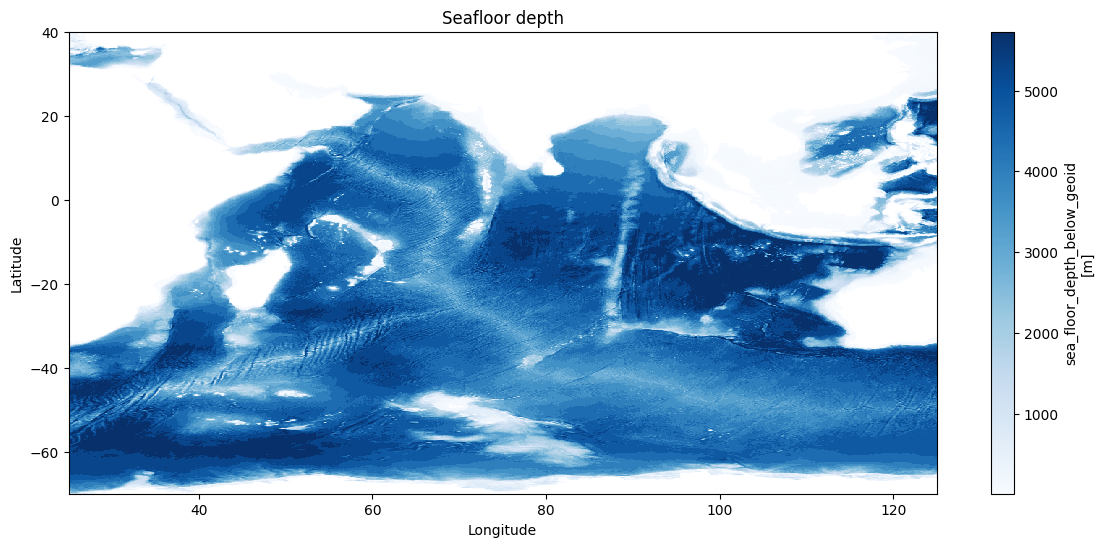

In [31]:
import matplotlib.pyplot as plt

#=======================================================
# define area of interest
lat_start = -70
lat_end   = 40
lon_start = 25
lon_end   = 125
#=======================================================

depth.plot(
    x="longitude",
    y="latitude",
    figsize=(14, 6),
    cmap="Blues",
    #robust=True
)



plt.title("Seafloor depth")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.xlim(lon_start, lon_end)
plt.ylim(lat_start, lat_end)
plt.show()

In [15]:
fig = go.Figure(data=seafloor)

fig.update_layout(title=dict(text='Mt Bruno Elevation'), autosize=True)#,
                  # width=500, height=500,
                  # margin=dict(l=65, r=50, b=65, t=90))

fig.show()

ValueError: 
    Invalid element(s) received for the 'data' property of 
        Invalid elements include: [<xarray.Dataset> Size: 2GB
Dimensions:     (latitude: 2041, longitude: 4320, depth: 50)
Coordinates:
  * longitude   (longitude) float32 17kB -180.0 -179.9 -179.8 ... 179.8 179.9
  * latitude    (latitude) float32 8kB -80.0 -79.92 -79.83 ... 89.83 89.92 90.0
  * depth       (depth) float32 200B 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
Data variables:
    deptho      (latitude, longitude) float64 71MB dask.array<chunksize=(2041, 4320), meta=np.ndarray>
    deptho_lev  (latitude, longitude) float64 71MB dask.array<chunksize=(2041, 4320), meta=np.ndarray>
    mask        (depth, latitude, longitude) int32 2GB dask.array<chunksize=(50, 2041, 4320), meta=np.ndarray>
Attributes:
    creation_date:  2023-02-25 23:31:32.146714
    author:         Mercator Ocean International
    references:     http://marine.copernicus.eu]

    The 'data' property is a tuple of trace instances
    that 

In [5]:
## Split with separated releases ## 

# Compute number of particles per location
particles_per_location = n_depths_per_location * num_pts

# Sanity check
total_particles_per_release = np.sum(particles_per_location)
print(f"Total particles per release for all locations: {total_particles_per_release}")
n_releases = ds.dims['trajectory'] // total_particles_per_release

print(f"Detected {n_releases} releases")

# Allocate list to hold output
split_by_location = []
loc_end_offset = []

offset = 0  # trajectory index offset
##location_release_offset = 0

for loc_idx in range(n_locations):
    loc_ds_list = []
    #location_release_offset = first loc_end of previous release 
    if loc_idx == 0:
        release_start = 0
    else:
        release_start = loc_end_offset[(loc_idx-1)*n_releases]  #release_idx * total_particles_per_release, +1 so indexes don't overlap
    ###print(f"release start of loc_idx loop {loc_idx} is {release_start}")
    for release_idx in range(n_releases):
        if release_idx == 0:
           loc_start = release_start
        else:
           loc_start = release_start + offset
           
        loc_end = loc_start + particles_per_location[loc_idx]
        
        ###print(f"{loc_idx}th location for {release_idx}th release: start index {loc_start} end index {loc_end}")
        loc_end_offset.append(loc_end)
        # select the trajectories for this location in this release
        ds_loc_release = ds.isel(trajectory=slice(loc_start, loc_end))


        #================
        # Stop trajectories from blowing up
        #ds_loc_release = ds_loc_release.transpose("trajectory", "obs") # Fix dimension ordering after slicing

        # Reset trajectory coordinate to match local indices (0 to N-1)
        n_traj = loc_end - loc_start
        ds_loc_release = ds_loc_release.assign_coords(trajectory=np.arange(n_traj))

        #================
        loc_ds_list.append(ds_loc_release)
        
        #offset += particles_per_location[loc_idx]  # prepare for next location in same release
        offset = (release_idx+1) * total_particles_per_release #11 so indexes don't overlap
        #release_start = release_idx * total_particles_per_release
        #release_start = release_idx * total_particles_per_release
        ###print(f"offset now {offset}")
        ###print(loc_end_offset)

    # concatenate all releases for this location along a new dimension
    ds_loc_all_releases = xr.concat(loc_ds_list, dim='release')
    # Add lat/lon metadata here:
    ds_loc_all_releases.attrs["site_index"] = loc_idx
    ds_loc_all_releases.attrs["vent_lon"] = vent_lon[loc_idx]
    ds_loc_all_releases.attrs["vent_lat"] = vent_lat[loc_idx]
    ds_loc_all_releases.attrs["n_depths"] = n_depths_per_location[loc_idx]

    # Remove unwanted attributes that don't carry over entire dataset
    for key in ["site_index", "vent_lon", "vent_lat", "n_depths"]:
        ds_loc_all_releases.attrs.pop(key, None)

    split_by_location.append(ds_loc_all_releases)
    

print("Split complete.")

# ====================

# Optionally combine all locations into a single dataset
ds_all_locations = xr.concat(split_by_location, dim='location')

# Assign useful coordinates
ds_all_locations = ds_all_locations.assign_coords(
    vent_lon=("location", vent_lon),
    vent_lat=("location", vent_lat),
    site_index=("location", np.arange(n_locations)),
    n_depths=("location", n_depths_per_location)
)

print("Combined dataset shape:")
print(ds_all_locations)

Total particles per release for all locations: 2630
Detected 30 releases


/scratch/ipykernel_754523/3980600915.py:9: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  n_releases = ds.dims['trajectory'] // total_particles_per_release


Split complete.


/home/l/lily-walker/.local/lib/python3.11/site-packages/dask/array/core.py:4849: PerformanceWarning: Increasing number of chunks by factor of 60
  result = blockwise(
/home/l/lily-walker/.local/lib/python3.11/site-packages/dask/array/core.py:4849: PerformanceWarning: Increasing number of chunks by factor of 60
  result = blockwise(
/home/l/lily-walker/.local/lib/python3.11/site-packages/dask/array/core.py:4849: PerformanceWarning: Increasing number of chunks by factor of 60
  result = blockwise(
/home/l/lily-walker/.local/lib/python3.11/site-packages/dask/array/core.py:4849: PerformanceWarning: Increasing number of chunks by factor of 60
  result = blockwise(
/home/l/lily-walker/.local/lib/python3.11/site-packages/dask/array/core.py:4849: PerformanceWarning: Increasing number of chunks by factor of 60
  result = blockwise(
/home/l/lily-walker/.local/lib/python3.11/site-packages/dask/array/core.py:4849: PerformanceWarning: Increasing number of chunks by factor of 60
  result = blockwise

Combined dataset shape:
<xarray.Dataset> Size: 3GB
Dimensions:     (location: 13, release: 30, trajectory: 260, obs: 720)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 713 714 715 716 717 718 719
  * trajectory  (trajectory) int64 2kB 0 1 2 3 4 5 6 ... 254 255 256 257 258 259
    vent_lon    (location) float64 104B 60.18 60.3 63.75 ... 79.1 50.24 49.39
    vent_lat    (location) float64 104B 6.8 6.363 3.75 ... -41.25 -37.39 -37.47
    site_index  (location) int64 104B 0 1 2 3 4 5 6 7 8 9 10 11 12
    n_depths    (location) int64 104B 23 23 26 23 19 19 16 26 26 23 19 10 10
Dimensions without coordinates: location, release
Data variables:
    d2s         (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
    d2seabed    (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
    dU          (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 1

In [6]:
ds_all_locations#.isel(location=5).isel(release=5)

<xarray.Dataset> Size: 3GB
Dimensions:     (location: 13, release: 30, trajectory: 260, obs: 720)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 713 714 715 716 717 718 719
  * trajectory  (trajectory) int64 2kB 0 1 2 3 4 5 6 ... 254 255 256 257 258 259
    vent_lon    (location) float64 104B 60.18 60.3 63.75 ... 79.1 50.24 49.39
    vent_lat    (location) float64 104B 6.8 6.363 3.75 ... -41.25 -37.39 -37.47
    site_index  (location) int64 104B 0 1 2 3 4 5 6 7 8 9 10 11 12
    n_depths    (location) int64 104B 23 23 26 23 19 19 16 26 26 23 19 10 10
Dimensions without coordinates: location, release
Data variables:
    d2s         (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
    d2seabed    (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
    dU          (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
    dV          (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
    dZ          (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
    lat         (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
    lon         (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
    temp        (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
    time        (location, release, trajectory, obs) datetime64[ns] 584MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
    z           (location, release, trajectory, obs) float32 292MB dask.array<chunksize=(1, 1, 16, 1), meta=np.ndarray>
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        DisplacementParticledisplacedisplace_zAdvectionRK...
    parcels_mesh:           spherical
    parcels_version:        3.0.4

## Flattening release dimension

In [ ]:
# === Flatten 'release' and 'trajectory' into a single 'trajectory' dimension ===

# Step 1: Stack 'release' and 'trajectory' into a new combined dimension
ds_flat = ds_all_locations.stack(trajectory_flat=("release", "trajectory"))

# Step 2: Drop the old 'trajectory' coordinate if it exists
if "trajectory" in ds_flat.coords:
    ds_flat = ds_flat.drop_vars("trajectory")

# Step 3: Rename the stacked dimension to just 'trajectory'
ds_flat = ds_flat.rename_dims({"trajectory_flat": "trajectory"})

# Step 4: Drop the 'trajectory_flat' coordinate if it's still there
if "trajectory_flat" in ds_flat.coords:
    ds_flat = ds_flat.drop_vars("trajectory_flat")

# Step 5: Assign new integer-based trajectory coordinate
n_traj = ds_flat.dims["trajectory"]
ds_flat = ds_flat.assign_coords(trajectory=np.arange(n_traj))

# === Now have (location, trajectory, obs) ===
print(ds_flat)


In [ ]:
# # Save as netcdf
# ds_flat.to_netcdf("output_split_flattened_" + output_name + ".nc", engine="netcdf4", compute=True)

In [ ]:
#ds_flat

# Plotting

In [ ]:
location = location #integer of vent, defined above

In [ ]:
import parcels
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import cmocean

from glob import glob
from copy import copy
from scipy import interpolate
from datetime import timedelta
from matplotlib.lines import Line2D


from parcels import (
    AdvectionRK4_3D,
    Field,
    FieldSet,
    Geographic,
    GeographicPolar,
    JITParticle,
    ParticleSet,
    ScipyParticle,
    Variable,
)

In [ ]:
ptcls = ds_flat.isel(location=location)#ds_all_locations.isel(location=1).isel(release=1)
#Once location is selected, can switch trajectory and obs around
ptcls = ptcls.transpose("trajectory", "obs")

In [ ]:
data_path_MERC = '/bucket/MitaraiU/Users/heng/GLORYS12/'
mask_bathy_path = data_path_MERC + 'GLO-MFC_001_024_mask_bathy.nc' 
mesh_mask_path = data_path_MERC + 'GLO-MFC_001_024_coordinates.nc'

# Load landmask and bathymetry
mask_bathy      = nc.Dataset(mask_bathy_path)

landmask = mask_bathy['mask']  # dim=(depth=50, lat=2041, lon=4320); Land: 0, Ocean: 1

# Make negative of land mask (i.e. Land: 1, Ocean: 0)
landmask_negative = 1 - landmask[:]

# Load coordinates file
mesh_mask = nc.Dataset(mesh_mask_path)

In [ ]:
# Velocity nodes
lon_vals, lat_vals = np.meshgrid(mask_bathy['longitude'], mask_bathy['latitude'])
lons_plot = lon_vals
lats_plot = lat_vals

# Centers of the gridcells formed by 4 nodes = velocity nodes + 0.5 dx
x = mask_bathy['longitude'][:-1] + np.diff(mask_bathy['longitude']) / 2
y = mask_bathy['latitude'][:-1] + np.diff(mask_bathy['latitude']) / 2
lon_centers, lat_centers = np.meshgrid(x, y)

# Choose land mask at depth closest to release depth
if release_depth == 'max_depth':
    mask_depth = 2000
else:
    mask_depth = release_depth
difference_array = np.abs(mesh_mask['depth'][:] - mask_depth)
index = difference_array.argmin()

# Interpolate landmask to cell centers
# -> Only cells with 4 neighboring land points will be land
fl = interpolate.RectBivariateSpline(
    mesh_mask['latitude'], mesh_mask['longitude'], landmask_negative[index], kx=1, ky=1
)

l_centers = fl(lat_centers[:, 0], lon_centers[0, :])

# land when interpolated value == 1
lmask = np.ma.masked_values(l_centers, 1)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

#=======================================================
# define area of interest
lat_start = -70
lat_end   = 40
lon_start = 25
lon_end   = 125
#=======================================================

# Observations and total time
observations = ptcls.dims['obs'] # Number of time observations #180*12 Read from the xarray
total_days = ptcls.dims['obs']/(24/time_step) # Total time in days (divide by hours)
particles = ptcls.dims['trajectory'] # Number of trajectories read from array

# Calculate drift time in days for each observation
drift_time_days = np.linspace(0, total_days, observations)  # Drift time over 64 days


# If relevent in the future
# /scratch/ipykernel_3087701/2116293271.py:13: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
# observations = ptcls.dims['obs'] # Number of time observations #180*12 Read from the xarray

## Plot on map

In [ ]:
# Plot on map

plt.figure(figsize=(20, 12))

# Plotting the map background
plt.pcolormesh(
    lon_vals,
    lat_vals,
    lmask.mask,
    cmap='Blues_r',
    alpha=.1
)

# Create a color array based on drift time in days
color_by_age = np.tile(drift_time_days, particles)

# Plot particles with drift time color coding (in days)
sc = plt.scatter(ptcls['lon'][:,:observations].values, ptcls['lat'][:,:observations].values, c=color_by_age, s=2, zorder=1, cmap='viridis')

# Plot initial positions of particles in red
plt.scatter(ptcls['lon'][:,0].values, ptcls['lat'][:,0].values, c='red', marker='x', s=10, zorder=3)

#=======================================================
# axis settings - making the axes more visible
plt.xlabel('Longitude [degrees]', fontsize=20)
plt.ylabel('Latitude [degrees]', fontsize=20)
plt.xlim(lon_start, lon_end)
plt.ylim(lat_start, lat_end)

# Adjusting tick label sizes for better visibility
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

#=======================================================
# Add a colorbar that reflects drift time in days
cbar = plt.colorbar(sc)
cbar.set_label('Drift Time [days]', fontsize=18)
cbar.ax.tick_params(labelsize=18)

# Title
plt.title(f"Path of {num_pts} particles released every {depth_interval}m every day for {release_period} days at Location {location}")
    
# Save plot
plt.savefig(f"plots/particle_drift_map_location{location}__output_{output_name}.png", dpi=300, bbox_inches="tight")
# Show plot
plt.show()


## Plot multiple depth

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(20, 12))

N = particles #if all particles
top_index = particles #if all particles
bottom_index = 0 #if all particles
#bottom_index = 35
#top_index = 45

# Extract x and y values for each trajectory
x_values = ptcls.time.values[bottom_index:top_index, :]  # Time values for all trajectories
y_values = ptcls.z.values[bottom_index:top_index, :]  # Temperature values for all trajectories
trajectories = ptcls.trajectory.values[bottom_index:top_index]  # Trajectories

# Use a colormap with more distinguishable colors (tab10 or tab20)
cmap = plt.cm.get_cmap('tab20', len(trajectories))  # Tab20 for distinct colors

# Reduce the dot size to make the plot look more like thin lines
dot_size = 0.5  # Smaller size for plot

# Plot each trajectory with a different color and smaller dot size (to appear as thin lines)
for i in range(len(trajectories)):
    plt.scatter(x_values[i, :], y_values[i, :], c=[cmap(i)], s=dot_size, label=f'Trajectory {i+1}')

# Axis labels with larger font size
plt.xlabel('Time', fontsize=20)
plt.ylabel('Depth (m)', fontsize=20)

# Increase the font size of the tick labels
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# # Create a customized legend with larger dots, but keep the plot markers smaller (thin lines)
# legend = plt.legend(fontsize=12, loc='upper right')

# # Manually adjust the marker size in the legend to be larger without affecting the plot
# for handle in legend.legendHandles:
#     handle._sizes = [100]  # Larger dot size in the legend (adjust this value as needed)

plt.title(f"Depths of {num_pts} particles released every {depth_interval}m every day for {release_period} days at Location {location}")

# Save plot
plt.savefig(f"plots/multipleparticle_depth_plot{location}__output_{output_name}.png", dpi=300, bbox_inches="tight")
# Show plot
plt.show()

# If relevent in future:
# /scratch/ipykernel_3087701/1935949611.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
# cmap = plt.cm.get_cmap('tab20', len(trajectories))  # Tab20 for distinct colors

## Plot multiple temperature

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(20, 12))

N = particles #if all particles
#N = 10

# Extract x and y values for each trajectory
x_values = ptcls.time.values[:N, :]  # Time values for all trajectories
y_values = ptcls.temp.values[:N, :]  # Temperature values for all trajectories
trajectories = ptcls.trajectory.values[:N]  # Trajectories

# Use a colormap with more distinguishable colors (tab10 or tab20)
cmap = plt.cm.get_cmap('tab20', len(trajectories))  # Tab20 for distinct colors

# Reduce the dot size to make the plot look more like thin lines
dot_size = 0.5  # Smaller size for plot

# Plot each trajectory with a different color and smaller dot size (to appear as thin lines)
for i in range(len(trajectories)):
    plt.scatter(x_values[i, :], y_values[i, :], c=[cmap(i)], s=dot_size, label=f'Trajectory {i+1}')

# Axis labels with larger font size
plt.xlabel('Time', fontsize=20)
plt.ylabel('Temperature (°C)', fontsize=20)

# Increase the font size of the tick labels
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# # Create a customized legend with larger dots, but keep the plot markers smaller (thin lines)
# legend = plt.legend(fontsize=12, loc='upper right')

# # Manually adjust the marker size in the legend to be larger without affecting the plot
# for handle in legend.legendHandles:
#     handle._sizes = [100]  # Larger dot size in the legend (adjust this value as needed)

plt.title(f"Temperature of {num_pts} particles released every {depth_interval}m every day for {release_period} days at Location {location}")

# Save plot
plt.savefig(f"plots/multipleparticle_temperature_plot_location{location}__output{output_name}.png", dpi=300, bbox_inches="tight")
# Show plot
plt.show()
